# GemmaForge token-level probe evaluation

This is the **new** evaluation path: it consumes the token-labeled dataset
(`data/dataset.jsonl`) and reports metrics at the three aggregation levels
from the hallucination-probes paper (Obeso et al. 2025, Section 4):

- **all** — every token in every example. In-span tokens are positive;
  out-of-span tokens are negative. Measures the probe's behaviour on
  *every* generated token, the way the streaming UI sees it.
- **span** — only tokens inside annotated spans. Single-class on the SVEN
  corpus (no sanitizer entries) → AUC is NaN here. Will become meaningful
  when we add sanitizer-annotated negatives.
- **span_max** — one decision per span. Positive examples contribute their
  evidence-span max; negative examples contribute a whole-file max
  (see `pad_negatives_for_span_max` in `token_protocol.py`).

The **old (sample-level) probe** runs as a `BroadcastProbeBaseline`: its
one-score-per-file output is broadcast to every token. That tells us
how much resolution the new token-level probe adds over the deployed
sample-level baseline.

## Important: status of inputs

To run this notebook end-to-end you need two `.npz` files that the
token-level probe pipeline produces:

1. `data/activations_v2/token_probs.npz` — per-row token probabilities.
2. `data/activations_v2/token_offsets.npz` — per-row `(T, 2)` char offsets.

Those files don't exist yet because the token-level extractor
(`src/extract_token_activations.py`) is broken — it ignores the new
`token_labels` fields and falls back to last-5-token labelling. See
[#17](https://github.com/peaktwilight/gemmaforge/issues/17).

So this notebook runs in two modes:

- **demo mode (default)** — synthesises oracle token scores from the real
  `dataset.jsonl` spans, so you can see the full table render.
- **real mode** — set `MODE = "real"` and point `TOKEN_PROBS_PATH` /
  `TOKEN_OFFSETS_PATH` at the extractor outputs once #17 lands.

## Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "src" / "eval").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import matplotlib.pyplot as plt

from src.eval import token_data, token_protocol, baselines as bl_mod
from src.eval.token_data import (
    parse_spans, char_spans_to_token_spans, POSITIVE_KEYS, NEGATIVE_KEYS,
)

DATASET_PATH = ROOT / "data/dataset.jsonl"

# Toggle this once #17 ships.
MODE = "demo"
TOKEN_PROBS_PATH = ROOT / "data/activations_v2/token_probs.npz"
TOKEN_OFFSETS_PATH = ROOT / "data/activations_v2/token_offsets.npz"

## Inspect the dataset

Quick structural check: row counts, span counts, label distribution by
span-source-key.

In [2]:
rows = token_data.load_token_dataset(DATASET_PATH)
print(f"rows total       = {len(rows)}")
print(f"label=1          = {sum(1 for r in rows if r['label']==1)}")
print(f"label=0          = {sum(1 for r in rows if r['label']==0)}")
print()
key_counts = {k: 0 for k in (*POSITIVE_KEYS, *NEGATIVE_KEYS)}
span_lens = {k: [] for k in (*POSITIVE_KEYS, *NEGATIVE_KEYS)}
for r in rows:
    tl = r.get("token_labels") or {}
    for k in key_counts:
        for span in tl.get(k, []) or []:
            key_counts[k] += 1
            span_lens[k].append(span[1] - span[0])
print("annotated span counts:")
for k, n in key_counts.items():
    if n:
        med = int(np.median(span_lens[k])) if span_lens[k] else 0
        print(f"  {k:18s}  n_spans={n:5d}  median_chars={med}")
    else:
        print(f"  {k:18s}  (none)")

rows total       = 1374
label=1          = 687
label=0          = 687

annotated span counts:
  evidence            n_spans= 3121  median_chars=3
  vulnerable_line     n_spans= 3121  median_chars=3
  sink                (none)
  source              (none)
  sanitizer           (none)


**Note.** The SVEN dataset has zero sanitizer spans, so the `span`
aggregation level reduces to "in-span positive tokens" only and AUC at
that level is undefined (single-class). For real binary classification
at span granularity, we synthesise a whole-file negative span per
`label=0` example inside `token_protocol`. The `all` and `span_max`
levels are the operational metrics on this corpus.

## Choose probe scores

In [3]:
if MODE == "real":
    npz_p = np.load(TOKEN_PROBS_PATH)
    npz_o = np.load(TOKEN_OFFSETS_PATH)
    probs_per_row = [npz_p[f"probs_row_{i}"] for i in range(len(rows))]
    offsets_per_row = [
        [(int(s), int(e)) for s, e in npz_o[f"offsets_row_{i}"]]
        for i in range(len(rows))
    ]
    print(f"loaded real token scores: {len(probs_per_row)} rows")
else:
    # Demo mode: synthesise oracle scores aligned to the real spans.
    rng = np.random.default_rng(13)
    probs_per_row = []
    offsets_per_row = []
    for r in rows:
        code = r["code"]
        if not code:
            probs_per_row.append(np.empty(0, dtype=np.float32))
            offsets_per_row.append([])
            continue
        step = max(1, len(code) // 256)
        offs = [(i, min(i + step, len(code))) for i in range(0, len(code), step)]
        n = len(offs)
        char_spans = parse_spans(r)
        tspans = char_spans_to_token_spans(char_spans, offs)
        probs = rng.uniform(0.0, 0.15, size=n)
        for s, e, lbl in tspans:
            e_c = min(e, n - 1)
            if e_c < s:
                continue
            if lbl == 1:
                probs[s : e_c + 1] = rng.uniform(0.85, 1.0, size=e_c + 1 - s)
        probs_per_row.append(probs.astype(np.float32))
        offsets_per_row.append(offs)
    print(f"synthesised oracle scores for {len(probs_per_row)} rows")

synthesised oracle scores for 1374 rows


## Build token spans + run the full report

In [4]:
token_spans_per_row = []
for r, offs in zip(rows, offsets_per_row):
    char_spans = parse_spans(r)
    token_spans_per_row.append(char_spans_to_token_spans(char_spans, offs))

# Baselines: trivial + (optional) old probe broadcast.
baselines = bl_mod.all_baselines()
sample_X = None
PROBE_PATH = ROOT / "data" / "probe.npz"
SAMPLE_ACTS = ROOT / "data" / "activations_v2" / "activations_layer17.npz"
if PROBE_PATH.exists() and SAMPLE_ACTS.exists() and MODE == "real":
    # Only meaningful if the sample-activations align row-for-row with the
    # token-level dataset. That requires re-extracting activations on
    # dataset.jsonl; the existing activations_v2 files are aligned to
    # pairs.jsonl, NOT dataset.jsonl. Disabled in demo mode.
    npz = np.load(SAMPLE_ACTS)
    if npz["X"].shape[0] == len(rows):
        baselines = bl_mod.with_probe_baseline(str(PROBE_PATH), broadcast=True)
        sample_X = npz["X"]
        print(f"old probe added as broadcast baseline ({sample_X.shape})")
    else:
        print(
            f"skipping ProbeBaseline: activations N={npz['X'].shape[0]} != "
            f"dataset N={len(rows)} (need re-extraction on dataset.jsonl)"
        )

full = token_protocol.full_token_report(
    rows, probs_per_row, token_spans_per_row,
    dataset_path=str(DATASET_PATH.relative_to(ROOT)),
    bootstrap_n=200,
    baselines=baselines,
    sample_X=sample_X,
)
print(f"ran {len(full.splits)} splits")

ran 12 splits


## Pretty-print the three-level table

In [5]:
print(f"{'split':32s}  {'level':10s}  {'AUC':>6s}  {'F1':>6s}  {'R@10':>6s}  {'n_tot':>7s}  {'n_pos':>6s}")
print("-" * 90)
for sp in full.splits:
    for level_name, m in (("all", sp.all_metrics), ("span", sp.span_metrics), ("span_max", sp.span_max_metrics)):
        if m.get("n_total", 0) == 0:
            continue
        auc = m.get("auc", float("nan"))
        f1 = m.get("f1", float("nan"))
        r10 = m.get("recall_at_fpr_0.10", float("nan"))
        print(
            f"{sp.split_name:32s}  {level_name:10s}  "
            f"{auc:6.3f}  {f1:6.3f}  {r10:6.3f}  "
            f"{m.get('n_total', 0):7d}  {m.get('n_pos', 0):6d}"
        )

split                             level          AUC      F1    R@10    n_tot   n_pos
------------------------------------------------------------------------------------------
random_stratified                 all          1.000   1.000   1.000    78746    2413
random_stratified                 span           nan   1.000     nan     2413    2413
random_stratified                 span_max     1.000   1.000   1.000      727     590
group_repo                        all          1.000   1.000   1.000    79099    2473
group_repo                        span           nan   1.000     nan     2473    2473
group_repo                        span_max     1.000   1.000   1.000      707     570
heldout_cwe::CWE-089              all          1.000   1.000   1.000   121582    3367
heldout_cwe::CWE-089              span           nan   1.000     nan     3367    3367
heldout_cwe::CWE-089              span_max     1.000   1.000   1.000     1169     965
heldout_cwe::CWE-125              all          1.

## Baselines comparison

In [6]:
print(f"{'split':32s}  {'baseline':24s}  {'all':>7s}  {'span':>7s}  {'span_max':>9s}")
print("-" * 90)
for sp in full.splits:
    for bl_name, lvls in sp.baseline_aucs.items():
        print(
            f"{sp.split_name:32s}  {bl_name:24s}  "
            f"{lvls.get('all_auc', float('nan')):7.3f}  "
            f"{lvls.get('span_auc', float('nan')):7.3f}  "
            f"{lvls.get('span_max_auc', float('nan')):9.3f}"
        )

split                             baseline                      all     span   span_max
------------------------------------------------------------------------------------------
random_stratified                 random                      0.420      nan        nan
random_stratified                 length                      0.376      nan        nan
random_stratified                 regex                       0.491      nan        nan
group_repo                        random                      0.475      nan        nan
group_repo                        length                      0.377      nan        nan
group_repo                        regex                       0.466      nan        nan
heldout_cwe::CWE-089              random                      0.511      nan        nan
heldout_cwe::CWE-089              length                      0.419      nan        nan
heldout_cwe::CWE-089              regex                       0.485      nan        nan
heldout_cwe::CWE-125         

## Headline plot: span_max AUC per split

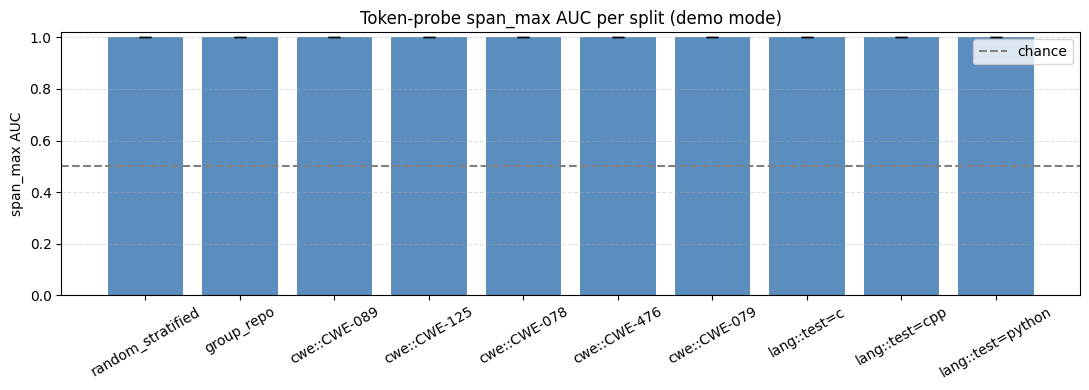

In [7]:
labels_x, values, errs = [], [], []
for sp in full.splits:
    m = sp.span_max_metrics
    auc = m.get("auc")
    if auc is None or (isinstance(auc, float) and np.isnan(auc)):
        continue
    labels_x.append(sp.split_name.replace("heldout_", ""))
    values.append(auc)
    lo, hi = m.get("auc_ci_lo", auc), m.get("auc_ci_hi", auc)
    errs.append([auc - lo, hi - auc])
errs = np.array(errs).T if errs else None

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(labels_x, values, color="#5b8dbe", yerr=errs, capsize=4)
ax.axhline(0.5, color="gray", linestyle="--", label="chance")
ax.set_ylim(0, 1.02)
ax.set_ylabel("span_max AUC")
ax.set_title(f"Token-probe span_max AUC per split ({MODE} mode)")
ax.tick_params(axis="x", rotation=30)
ax.legend()
ax.grid(True, axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## Save report

In [8]:
out_md = ROOT / "data/eval/token_report.md"
out_json = ROOT / "data/eval/token_report.json"
out_md.parent.mkdir(parents=True, exist_ok=True)
out_json.write_text(json.dumps(full.to_dict(), indent=2, default=str))
# Compact markdown.
lines = [
    "# Token-level probe evaluation report",
    "",
    f"Dataset: `{DATASET_PATH.relative_to(ROOT)}` (N={full.n_examples}, pos={full.n_pos_examples})",
    f"Mode: `{MODE}`",
    "",
    "| split | level | AUC (95% CI) | F1 | R@10%FPR | n_total | n_pos |",
    "|---|---|---|---|---|---:|---:|",
]
for sp in full.splits:
    for level_name, m in (("all", sp.all_metrics), ("span", sp.span_metrics), ("span_max", sp.span_max_metrics)):
        if m.get("n_total", 0) == 0:
            continue
        auc = m.get("auc", float("nan"))
        lo = m.get("auc_ci_lo", float("nan"))
        hi = m.get("auc_ci_hi", float("nan"))
        f1 = m.get("f1", float("nan"))
        r10 = m.get("recall_at_fpr_0.10", float("nan"))
        lines.append(
            f"| `{sp.split_name}` | {level_name} | "
            f"{auc:.3f} ({lo:.3f}-{hi:.3f}) | {f1:.3f} | {r10:.3f} | "
            f"{m.get('n_total', 0)} | {m.get('n_pos', 0)} |"
        )
out_md.write_text("\n".join(lines) + "\n")
print(f"wrote {out_md}")
print(f"wrote {out_json}")

wrote /Users/mmtf/p/tmp/2026-05-18-peaktwilight-gemmaforge/data/eval/token_report.md
wrote /Users/mmtf/p/tmp/2026-05-18-peaktwilight-gemmaforge/data/eval/token_report.json
